# Forecasting

In [12]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

In [13]:
OUTPUTS = PROJECT_ROOT / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)

In [14]:
from src.experiments.artifacts import ReconstructedStore

store = ReconstructedStore(OUTPUTS / "reconstructed")

In [15]:
import pandas as pd
import numpy as np

Repeat code from `imputation.ipynb`.

In [16]:
from src.data import load_ett, chronological_split, scale

train, test = chronological_split(load_ett())
train_s, test_s, scaler = scale(train=train, test=test)

Set horizon length.

In [17]:
H = 24 * 7

In [18]:
truth = test_s["OT"].iloc[:H].to_numpy()

### Baseline Forecast with Original Complete Data

**Exponential Smoothing**

In [19]:
from src.forecasters.exp_smoothing import ExpSmoothingForecaster

exp_base = ExpSmoothingForecaster(seasonal_periods=24, seasonal="add", trend="add", damped_trend=True)
exp_base.fit(train_s)
exp_base_forecast = exp_base.predict(horizon=H)

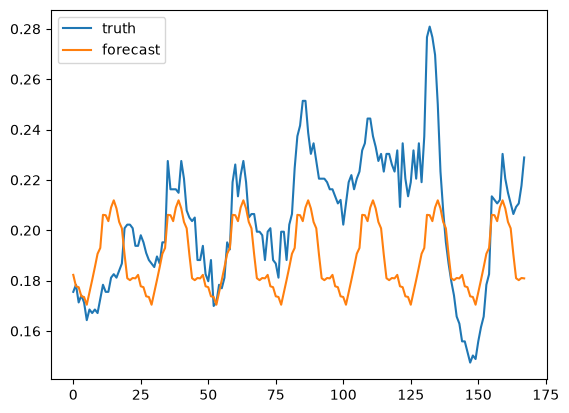

In [20]:
import matplotlib.pyplot as plt

plt.plot(truth, label="truth")
plt.plot(exp_base_forecast, label="forecast")
plt.legend()
plt.show()

In [21]:
np.sqrt(np.mean((exp_base_forecast - truth)**2))

np.float64(0.027124516363653085)

**XGBoost**

In [22]:
from src.forecasters.xgb import XGBoostForecaster

xgb_base = XGBoostForecaster()
xgb_base_trained = xgb_base.fit(train_s)
xgb_base_forecast = xgb_base_trained.predict(horizon=H)

### Forecasting Experiment

In [ ]:
from src.experiments.forecasting import ForecastingExperiment
from src.forecasters import FORECASTERS

baselines = {
    "exp_smoothing": exp_base_forecast,
    "xgboost": xgb_base_forecast,
}

experiment = ForecastingExperiment(forecasters=list(FORECASTERS))
bv_df = experiment.run(horizon=H, store=store, truth=truth, baselines=baselines)

bv_df.to_parquet(OUTPUTS / "bias_variance.parquet")
bv_df